In [1]:
# Simulation study for FAME — imports and environment
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, KFold
from sklearn.inspection import permutation_importance
import shap
import os
import warnings
warnings.filterwarnings('ignore')

# Reproducibility
MASTER_SEED = 42
np.random.seed(MASTER_SEED)

# Paths
RESULTS_DIR = 'results'
FIGURES_DIR = os.path.join(RESULTS_DIR, 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

# Version check — this will appear in the manuscript
import sklearn, scipy
print(f"numpy        {np.__version__}")
print(f"pandas       {pd.__version__}")
print(f"scipy        {scipy.__version__}")
print(f"scikit-learn {sklearn.__version__}")
print(f"shap         {shap.__version__}")
print(f"matplotlib   {plt.matplotlib.__version__}")
print(f"\nResults will be saved to: {os.path.abspath(RESULTS_DIR)}")

numpy        2.4.6
pandas       3.0.5
scipy        1.17.1
scikit-learn 1.9.0
shap         0.51.0
matplotlib   3.11.1

Results will be saved to: /home/mb/ML_analysis/streamlit_app/simulation/results


In [2]:
# Simulation design specification
FACTOR_NAMES = ['A', 'B', 'C', 'D']

# Ground-truth effect coefficients, in units of residual SD.
# For a 2-level factor coded as -1 / +1, the coefficient equals
# half the difference between the two level means, and Cohen's f ≈ coefficient.
EFFECTS = {
    'A':    0.40,   # strong main effect
    'B':    0.25,   # moderate main effect
    'C':    0.15,   # weak main effect
    'D':    0.00,   # null main effect
    'A:B':  0.15,   # weak two-way interaction
    'A:C':  0.00,
    'A:D':  0.00,
    'B:C':  0.00,
    'B:D':  0.00,
    'C:D':  0.00,
}

RESIDUAL_SD = 1.0
SAMPLE_SIZES = [32, 64, 96, 128]
N_ITERATIONS = 500

# Summary printout
print("Factors:", FACTOR_NAMES)
print(f"Design: 2 x 2 x 2 x 2 = {2**len(FACTOR_NAMES)} cells\n")

print("Ground-truth effect coefficients (residual SD units):")
for k, v in EFFECTS.items():
    if v == 0:
        label = 'null'
    elif v < 0.2:
        label = 'weak'
    elif v < 0.35:
        label = 'moderate'
    else:
        label = 'strong'
    print(f"  {k:5s}  {v:.2f}  ({label})")

print(f"\nResidual SD: {RESIDUAL_SD}")
print(f"Sample sizes: {SAMPLE_SIZES}")
print(f"Iterations per scenario: {N_ITERATIONS}")
print(f"Total runs: {len(SAMPLE_SIZES) * N_ITERATIONS}")

Factors: ['A', 'B', 'C', 'D']
Design: 2 x 2 x 2 x 2 = 16 cells

Ground-truth effect coefficients (residual SD units):
  A      0.40  (strong)
  B      0.25  (moderate)
  C      0.15  (weak)
  D      0.00  (null)
  A:B    0.15  (weak)
  A:C    0.00  (null)
  A:D    0.00  (null)
  B:C    0.00  (null)
  B:D    0.00  (null)
  C:D    0.00  (null)

Residual SD: 1.0
Sample sizes: [32, 64, 96, 128]
Iterations per scenario: 500
Total runs: 2000


In [3]:
# Data generator: builds a balanced 2x2x2x2 factorial dataset
# with known ground-truth effects.

def build_design():
    """Return the 16-cell 2x2x2x2 design with factors coded -1 / +1."""
    from itertools import product
    cells = list(product([-1, +1], repeat=4))
    return pd.DataFrame(cells, columns=FACTOR_NAMES)


def generate_dataset(n_total, effects, residual_sd, seed):
    """
    Generate one simulated dataset.
    
    Parameters
    ----------
    n_total : int       Total sample size (must be divisible by 16)
    effects : dict      Ground-truth coefficients, keyed by factor
                        name ('A') or interaction ('A:B')
    residual_sd : float SD of Gaussian noise
    seed : int          RNG seed for reproducibility
    
    Returns
    -------
    df : DataFrame      Columns: A, B, C, D, Y
    """
    if n_total % 16 != 0:
        raise ValueError(f"n_total={n_total} is not divisible by 16")
    n_per_cell = n_total // 16
    
    design = build_design()
    df = design.loc[design.index.repeat(n_per_cell)].reset_index(drop=True)
    
    rng = np.random.default_rng(seed)
    y = np.zeros(len(df))
    
    # Main effects
    for f in FACTOR_NAMES:
        coef = effects.get(f, 0.0)
        y += coef * df[f].values
    
    # Two-way interactions
    for i, fi in enumerate(FACTOR_NAMES):
        for fj in FACTOR_NAMES[i+1:]:
            key = f"{fi}:{fj}"
            coef = effects.get(key, 0.0)
            if coef != 0.0:
                y += coef * df[fi].values * df[fj].values
    
    # Residual
    y += rng.normal(0.0, residual_sd, size=len(df))
    
    df['Y'] = y
    return df


# Sanity check: generate one dataset and inspect it
test_df = generate_dataset(n_total=32, effects=EFFECTS,
                            residual_sd=RESIDUAL_SD, seed=1)
print("First 8 rows:")
print(test_df.head(8).to_string(index=False))
print(f"\nShape: {test_df.shape}")
print(f"Y mean: {test_df['Y'].mean():.3f}")
print(f"Y SD:   {test_df['Y'].std():.3f}")
print(f"\nCell counts:")
print(test_df.groupby(FACTOR_NAMES).size().value_counts())

First 8 rows:
 A  B  C  D         Y
-1 -1 -1 -1 -0.304416
-1 -1 -1 -1  0.171618
-1 -1 -1  1 -0.319563
-1 -1 -1  1 -1.953157
-1 -1  1 -1  0.555356
-1 -1  1 -1  0.096375
-1 -1  1  1 -0.886953
-1 -1  1  1  0.231118

Shape: (32, 5)
Y mean: -0.031
Y SD:   0.980

Cell counts:
2    16
Name: count, dtype: int64


In [4]:
# Analysis function: given one dataset, run ANOVA + SHAP + permutation + CV
# and return per-effect statistics.

import statsmodels.api as sm
import statsmodels.formula.api as smf
from itertools import combinations


def analyse_dataset(df, factors=FACTOR_NAMES, cv_folds=5, rf_estimators=200,
                    perm_repeats=20, random_state=42):

    """
    Run the full FAME-style analysis on one dataset.
    
    Returns
    -------
    dict with keys:
      'anova_p'    : dict[effect_name] = p-value
      'anova_eta'  : dict[effect_name] = partial eta-squared
      'shap_pct'   : dict[factor_name] = normalized SHAP importance %
      'perm_pct'   : dict[factor_name] = normalized permutation importance %
      'cv_r2'      : dict[model_name]  = mean CV R²
    """
    result = {'anova_p': {}, 'anova_eta': {}, 'shap_pct': {},
              'perm_pct': {}, 'cv_r2': {}}
    
    # ---- ANOVA (all main effects + all 2-way interactions) ----
    main = ' + '.join(factors)
    inter = ' + '.join([f'{a}:{b}' for a, b in combinations(factors, 2)])
    formula = f'Y ~ {main} + {inter}'
    
    model = smf.ols(formula, data=df).fit()
    aov = sm.stats.anova_lm(model, typ=2)
    ss_err = aov.loc['Residual', 'sum_sq']
    
    for term in aov.index:
        if term == 'Residual':
            continue
        p = aov.loc[term, 'PR(>F)']
        eta = aov.loc[term, 'sum_sq'] / (aov.loc[term, 'sum_sq'] + ss_err)
        key = term.replace(' ', '')
        result['anova_p'][key] = float(p)
        result['anova_eta'][key] = float(eta)
    
    # ---- Feature matrix for ML ----
    X = df[factors].values.astype(float)
    y = df['Y'].values.astype(float)
    
    # ---- SHAP ----
    rf = RandomForestRegressor(n_estimators=rf_estimators, max_depth=None,
                               min_samples_leaf=2, random_state=random_state,
                               n_jobs=-1)
    rf.fit(X, y)
    explainer = shap.TreeExplainer(rf)
    shap_vals = np.abs(explainer.shap_values(X)).mean(axis=0)
    shap_pct = 100 * shap_vals / shap_vals.sum()
    result['shap_pct'] = {f: float(v) for f, v in zip(factors, shap_pct)}
    
    # ---- Permutation importance ----
    perm = permutation_importance(rf, X, y, n_repeats=perm_repeats,
                                  random_state=random_state, scoring='r2')
    perm_raw = np.maximum(perm.importances_mean, 0)
    if perm_raw.sum() > 0:
        perm_pct = 100 * perm_raw / perm_raw.sum()
    else:
        perm_pct = np.zeros_like(perm_raw)
    result['perm_pct'] = {f: float(v) for f, v in zip(factors, perm_pct)}
    
    # ---- CV model comparison ----
    cv = KFold(n_splits=cv_folds, shuffle=True, random_state=random_state)
    
    rf_cv = cross_val_score(
        RandomForestRegressor(n_estimators=rf_estimators, max_depth=None,
                              min_samples_leaf=2, random_state=random_state,
                              n_jobs=-1),
        X, y, cv=cv, scoring='r2').mean()
    
    lr_cv = cross_val_score(LinearRegression(), X, y, cv=cv, scoring='r2').mean()
    
    result['cv_r2'] = {'RF': float(rf_cv), 'LR': float(lr_cv)}
    
    return result


# Sanity check on the test dataset
print("Running analysis on the test dataset...")
test_result = analyse_dataset(test_df)
print("\nANOVA p-values:")
for k, v in test_result['anova_p'].items():
    print(f"  {k:5s}  p = {v:.4f}")
print("\nSHAP importance (%):")
for k, v in test_result['shap_pct'].items():
    print(f"  {k:5s}  {v:.2f}")
print("\nCV R²:")
for k, v in test_result['cv_r2'].items():
    print(f"  {k:4s}  {v:.3f}")

Running analysis on the test dataset...

ANOVA p-values:
  A      p = 0.1007
  B      p = 0.6063
  C      p = 0.0055
  D      p = 0.4033
  A:B    p = 0.7530
  A:C    p = 0.0263
  A:D    p = 0.0623
  B:C    p = 0.9841
  B:D    p = 0.1264
  C:D    p = 0.6844

SHAP importance (%):
  A      29.00
  B      6.82
  C      50.97
  D      13.21

CV R²:
  RF    -0.424
  LR    -0.357


In [6]:
# Smoke test: run the analysis loop with 20 iterations at n=32 only.
# This validates the code path before committing to a long run.

import time
from tqdm.notebook import tqdm

def run_scenario(n_total, n_iter, verbose=True):
    """Run n_iter simulations at sample size n_total; return aggregated metrics."""
    anova_p_records = []
    shap_records = []
    perm_records = []
    cv_records = []
    
    iterator = range(n_iter)
    if verbose:
        iterator = tqdm(iterator, desc=f"n={n_total}")
    
    for it in iterator:
        df = generate_dataset(n_total, EFFECTS, RESIDUAL_SD,
                              seed=MASTER_SEED + it + n_total * 10000)
        res = analyse_dataset(df, random_state=42)
        anova_p_records.append(res['anova_p'])
        shap_records.append(res['shap_pct'])
        perm_records.append(res['perm_pct'])
        cv_records.append(res['cv_r2'])
    
    return {
        'n': n_total,
        'n_iter': n_iter,
        'anova_p': pd.DataFrame(anova_p_records),
        'shap_pct': pd.DataFrame(shap_records),
        'perm_pct': pd.DataFrame(perm_records),
        'cv_r2': pd.DataFrame(cv_records),
    }


# Smoke test with 20 iterations at n=32 only
t0 = time.time()
smoke = run_scenario(n_total=32, n_iter=20, verbose=True)
elapsed = time.time() - t0

print(f"\nCompleted 20 iterations in {elapsed:.1f} seconds")
print(f"Estimated time for full study: "
      f"{elapsed * (len(SAMPLE_SIZES) * N_ITERATIONS / 20) / 60:.1f} minutes\n")

# Quick summary of this scenario
print("Mean SHAP importance (%) across 20 runs at n=32:")
print(smoke['shap_pct'].mean().round(2).to_string())
print("\nTrue effects for reference:")
for f in FACTOR_NAMES:
    print(f"  {f}: {EFFECTS[f]}")

n=32:   0%|          | 0/20 [00:00<?, ?it/s]


Completed 20 iterations in 275.2 seconds
Estimated time for full study: 458.6 minutes

Mean SHAP importance (%) across 20 runs at n=32:
A    37.48
B    26.76
C    20.35
D    15.40

True effects for reference:
  A: 0.4
  B: 0.25
  C: 0.15
  D: 0.0


In [7]:
# Parallel version of run_scenario using joblib.
# Each iteration is independent, so we can run them across all CPU cores.

from joblib import Parallel, delayed
import multiprocessing

N_CORES = multiprocessing.cpu_count()
print(f"Available CPU cores: {N_CORES}\n")


def _single_iteration(n_total, seed):
    """Run one full iteration; returns a flat dict of results."""
    df = generate_dataset(n_total, EFFECTS, RESIDUAL_SD, seed=seed)
    res = analyse_dataset(df, random_state=42)
    flat = {}
    for k, v in res['anova_p'].items():
        flat[f'anova_p__{k}'] = v
    for k, v in res['anova_eta'].items():
        flat[f'anova_eta__{k}'] = v
    for k, v in res['shap_pct'].items():
        flat[f'shap__{k}'] = v
    for k, v in res['perm_pct'].items():
        flat[f'perm__{k}'] = v
    for k, v in res['cv_r2'].items():
        flat[f'cv__{k}'] = v
    return flat


def run_scenario_parallel(n_total, n_iter, n_jobs=N_CORES, verbose=True):
    """Run n_iter simulations at sample size n_total in parallel."""
    seeds = [MASTER_SEED + it + n_total * 10000 for it in range(n_iter)]
    
    if verbose:
        print(f"Running {n_iter} iterations at n={n_total} "
              f"across {n_jobs} cores...")
    
    results = Parallel(n_jobs=n_jobs, verbose=5)(
        delayed(_single_iteration)(n_total, s) for s in seeds
    )
    
    return pd.DataFrame(results)


# Smoke test: 20 iterations at n=32 in parallel
t0 = time.time()
smoke_par = run_scenario_parallel(n_total=32, n_iter=20, verbose=True)
elapsed = time.time() - t0

print(f"\nCompleted 20 iterations in {elapsed:.1f} seconds "
      f"({elapsed/20:.2f} s/iteration effective)")
print(f"Estimated time for full study (2000 runs): "
      f"{elapsed * (len(SAMPLE_SIZES) * N_ITERATIONS / 20) / 60:.1f} minutes")

print(f"\nRows in result DataFrame: {len(smoke_par)}")
print(f"Columns: {len(smoke_par.columns)}")
print("\nFirst 3 column names:", list(smoke_par.columns[:3]))

Available CPU cores: 4

Running 20 iterations at n=32 across 4 cores...


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   47.3s
[Parallel(n_jobs=4)]: Done  18 out of  20 | elapsed:  1.2min remaining:    7.7s



Completed 20 iterations in 69.3 seconds (3.46 s/iteration effective)
Estimated time for full study (2000 runs): 115.5 minutes

Rows in result DataFrame: 20
Columns: 30

First 3 column names: ['anova_p__A', 'anova_p__B', 'anova_p__C']


[Parallel(n_jobs=4)]: Done  20 out of  20 | elapsed:  1.2min finished


In [8]:
# Aggregation: turn the raw iteration DataFrame into summary tables.

def aggregate_results(df_results):
    """
    Given a DataFrame from run_scenario_parallel (one row per iteration),
    produce summary tables for the manuscript.
    
    Returns a dict of DataFrames:
      'power'      : fraction of iterations with p < 0.05, per effect
      'type_i_error': same, for null effects only
      'shap_mean'  : mean SHAP importance per factor
      'shap_sd'    : SD of SHAP importance per factor
      'perm_mean'  : mean permutation importance
      'rank_recovery': mean rank agreement (Spearman) between
                        SHAP importances and true effects
    """
    effects_all = list(EFFECTS.keys())
    factors_only = FACTOR_NAMES.copy()
    
    # ---- Power / Type I error per effect ----
    power_row = {}
    for eff in effects_all:
        col = f'anova_p__{eff}'
        if col in df_results.columns:
            power_row[eff] = float((df_results[col] < 0.05).mean())
    power_df = pd.DataFrame(power_row, index=['power']).T
    
    # Split into "true effects" and "null effects"
    true_effects = [e for e in effects_all if EFFECTS[e] > 0]
    null_effects = [e for e in effects_all if EFFECTS[e] == 0]
    
    type_i_error = {e: power_row[e] for e in null_effects if e in power_row}
    power_true = {e: power_row[e] for e in true_effects if e in power_row}
    
    # ---- SHAP summaries ----
    shap_cols = [f'shap__{f}' for f in factors_only]
    shap_mean = df_results[shap_cols].mean().rename(
        {f'shap__{f}': f for f in factors_only})
    shap_sd = df_results[shap_cols].std().rename(
        {f'shap__{f}': f for f in factors_only})
    
    # ---- Permutation summaries ----
    perm_cols = [f'perm__{f}' for f in factors_only]
    perm_mean = df_results[perm_cols].mean().rename(
        {f'perm__{f}': f for f in factors_only})
    
    # ---- Rank recovery (Spearman between SHAP and true effect magnitudes) ----
    true_effects_vec = np.array([abs(EFFECTS[f]) for f in factors_only])
    
    def spearman_with_truth(row):
        shap_vec = np.array([row[f'shap__{f}'] for f in factors_only])
        if np.std(shap_vec) == 0 or np.std(true_effects_vec) == 0:
            return np.nan
        return stats.spearmanr(true_effects_vec, shap_vec).statistic
    
    rank_corrs = df_results.apply(spearman_with_truth, axis=1)
    
    return {
        'power': power_df,
        'power_true': power_true,
        'type_i_error': type_i_error,
        'shap_mean': shap_mean,
        'shap_sd': shap_sd,
        'perm_mean': perm_mean,
        'rank_recovery_mean': float(rank_corrs.mean()),
        'rank_recovery_sd': float(rank_corrs.std()),
    }


# Test on smoke data (n=32, 20 iterations)
agg_smoke = aggregate_results(smoke_par)

print("=== Smoke test aggregation (n=32, 20 iterations) ===\n")
print("Power for true effects:")
for k, v in agg_smoke['power_true'].items():
    print(f"  {k:5s}  {v:.2f}   (true effect = {EFFECTS[k]})")

print("\nType I error for null effects (should be ~0.05):")
for k, v in agg_smoke['type_i_error'].items():
    print(f"  {k:5s}  {v:.2f}")

print("\nMean SHAP importance (%):")
print(agg_smoke['shap_mean'].round(2).to_string())

print("\nMean permutation importance (%):")
print(agg_smoke['perm_mean'].round(2).to_string())

print(f"\nRank recovery (Spearman ρ between true effects and SHAP):")
print(f"  mean = {agg_smoke['rank_recovery_mean']:.3f}  "
      f"sd = {agg_smoke['rank_recovery_sd']:.3f}")

=== Smoke test aggregation (n=32, 20 iterations) ===

Power for true effects:
  A      0.45   (true effect = 0.4)
  B      0.25   (true effect = 0.25)
  C      0.15   (true effect = 0.15)
  A:B    0.20   (true effect = 0.15)

Type I error for null effects (should be ~0.05):
  D      0.00
  A:C    0.00
  A:D    0.05
  B:C    0.05
  B:D    0.15
  C:D    0.00

Mean SHAP importance (%):
A    37.48
B    26.76
C    20.35
D    15.40

Mean permutation importance (%):
A    38.76
B    27.31
C    19.36
D    14.57

Rank recovery (Spearman ρ between true effects and SHAP):
  mean = 0.550  sd = 0.410


In [11]:
import os
import pickle
import shutil
from datetime import datetime

# Ensure paths are defined (safe to re-run)
RESULTS_DIR = 'results'
FIGURES_DIR = os.path.join(RESULTS_DIR, 'figures')
SCENARIO_DIR = os.path.join(RESULTS_DIR, 'scenarios')
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(SCENARIO_DIR, exist_ok=True)

print(f"RESULTS_DIR  = {RESULTS_DIR}")
print(f"FIGURES_DIR  = {FIGURES_DIR}")
print(f"SCENARIO_DIR = {SCENARIO_DIR}")
print(f"Exists: {os.path.exists(SCENARIO_DIR)}")
print(f"Contents of SCENARIO_DIR: {os.listdir(SCENARIO_DIR)}")

RESULTS_DIR  = results
FIGURES_DIR  = results/figures
SCENARIO_DIR = results/scenarios
Exists: True
Contents of SCENARIO_DIR: ['scenario_n32.pkl', 'scenario_n64.pkl', 'scenario_n96.pkl', 'scenario_n128.pkl']


In [12]:
# Full re-run with pipeline-matched hyperparameters.
# Old scenarios (100 trees, 10 repeats) moved to results/scenarios_v1/.

import os
import pickle
import shutil
from datetime import datetime

backup_dir = os.path.join(RESULTS_DIR, 'scenarios_v1')
backup_dir = os.path.join(RESULTS_DIR, 'scenarios_v1')
if not os.path.exists(backup_dir):
    if os.path.exists(SCENARIO_DIR):
        shutil.move(SCENARIO_DIR, backup_dir)
        print(f"Moved old scenarios to {backup_dir}")
    else:
        print(f"No scenarios directory to move")
else:
    print(f"Backup already exists at {backup_dir}, keeping both")

os.makedirs(SCENARIO_DIR, exist_ok=True)

print(f"\nStarting fresh run with matched hyperparameters:")
print(f"  rf_estimators = 200")
print(f"  perm_repeats  = 20")
print(f"  N_ITERATIONS  = {N_ITERATIONS}")
print(f"  Sample sizes  = {SAMPLE_SIZES}")
print(f"  Estimated time: ~2 hours\n")
print(f"Started at {datetime.now().strftime('%H:%M:%S')}")

all_scenarios_v2 = {}
for n in SAMPLE_SIZES:
    out_path = os.path.join(SCENARIO_DIR, f'scenario_n{n}.pkl')
    if os.path.exists(out_path):
        print(f"n={n}: already saved, loading")
        with open(out_path, 'rb') as f:
            all_scenarios_v2[n] = pickle.load(f)
        continue
    
    t0 = time.time()
    print(f"\n=== Scenario n={n} starting ===")
    df_res = run_scenario_parallel(n_total=n, n_iter=N_ITERATIONS, verbose=True)
    elapsed = time.time() - t0
    
    with open(out_path, 'wb') as f:
        pickle.dump(df_res, f)
    
    all_scenarios_v2[n] = df_res
    print(f"n={n}: done in {elapsed/60:.1f} min")

print(f"\nAll scenarios complete at {datetime.now().strftime('%H:%M:%S')}")



Moved old scenarios to results/scenarios_v1

Starting fresh run with matched hyperparameters:
  rf_estimators = 200
  perm_repeats  = 20
  N_ITERATIONS  = 500
  Sample sizes  = [32, 64, 96, 128]
  Estimated time: ~2 hours

Started at 01:06:40

=== Scenario n=32 starting ===
Running 500 iterations at n=32 across 4 cores...


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   53.9s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:  3.4min
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:  7.6min
[Parallel(n_jobs=4)]: Done 280 tasks      | elapsed: 13.1min
[Parallel(n_jobs=4)]: Done 442 tasks      | elapsed: 20.3min
[Parallel(n_jobs=4)]: Done 500 out of 500 | elapsed: 22.9min finished
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.


n=32: done in 22.9 min

=== Scenario n=64 starting ===
Running 500 iterations at n=64 across 4 cores...


[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   32.4s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:  2.8min
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:  6.9min
[Parallel(n_jobs=4)]: Done 280 tasks      | elapsed: 12.4min
/home/mb/.conda/envs/ml_env/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/mb/.conda/envs/ml_env/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/mb/.conda/envs/ml_env/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.del

n=64: done in 22.2 min

=== Scenario n=96 starting ===
Running 500 iterations at n=96 across 4 cores...


[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   32.5s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:  2.9min
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:  7.0min
[Parallel(n_jobs=4)]: Done 280 tasks      | elapsed: 12.5min
[Parallel(n_jobs=4)]: Done 442 tasks      | elapsed: 19.7min
[Parallel(n_jobs=4)]: Done 500 out of 500 | elapsed: 22.3min finished
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.


n=96: done in 22.3 min

=== Scenario n=128 starting ===
Running 500 iterations at n=128 across 4 cores...


[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   32.5s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:  2.9min
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:  7.1min
[Parallel(n_jobs=4)]: Done 280 tasks      | elapsed: 12.7min
[Parallel(n_jobs=4)]: Done 442 tasks      | elapsed: 20.1min


n=128: done in 22.7 min

All scenarios complete at 02:36:40


[Parallel(n_jobs=4)]: Done 500 out of 500 | elapsed: 22.7min finished


In [13]:
# Reload everything from the new scenarios (matched hyperparameters).

import os
import pickle
import numpy as np
import pandas as pd
from scipy import stats

RESULTS_DIR = 'results'
SCENARIO_DIR = os.path.join(RESULTS_DIR, 'scenarios')
SAMPLE_SIZES = [32, 64, 96, 128]
FACTOR_NAMES = ['A', 'B', 'C', 'D']
EFFECTS = {
    'A': 0.40, 'B': 0.25, 'C': 0.15, 'D': 0.00,
    'A:B': 0.15, 'A:C': 0.00, 'A:D': 0.00,
    'B:C': 0.00, 'B:D': 0.00, 'C:D': 0.00,
}

# Load
scenarios = {}
for n in SAMPLE_SIZES:
    path = os.path.join(SCENARIO_DIR, f'scenario_n{n}.pkl')
    with open(path, 'rb') as f:
        scenarios[n] = pickle.load(f)
    print(f"n={n}: {len(scenarios[n])} iterations loaded")

# Power table
def build_power_table(scenarios):
    rows = {}
    for eff in EFFECTS:
        col = f'anova_p__{eff}'
        rows[eff] = {n: (scenarios[n][col] < 0.05).mean()
                     for n in SAMPLE_SIZES}
    df = pd.DataFrame(rows).T
    df.insert(0, 'true_effect', [EFFECTS[e] for e in df.index])
    return df

power_table = build_power_table(scenarios)

print("\n=== Power table (fraction p<0.05) ===\n")
print(power_table.round(3).to_string())

# Type I error summary
null_effects = [e for e in EFFECTS if EFFECTS[e] == 0]
tie_table = pd.DataFrame({
    n: {e: (scenarios[n][f'anova_p__{e}'] < 0.05).mean()
        for e in null_effects}
    for n in SAMPLE_SIZES
})
print("\n=== Type I error table (null effects) ===\n")
print(tie_table.round(3).to_string())
print(f"\nMean across all null effects and scenarios: "
      f"{tie_table.values.mean():.3f}")

n=32: 500 iterations loaded
n=64: 500 iterations loaded
n=96: 500 iterations loaded
n=128: 500 iterations loaded

=== Power table (fraction p<0.05) ===

     true_effect     32     64     96    128
A           0.40  0.616  0.888  0.964  0.992
B           0.25  0.300  0.514  0.676  0.784
C           0.15  0.100  0.226  0.296  0.400
D           0.00  0.058  0.058  0.052  0.042
A:B         0.15  0.120  0.220  0.290  0.360
A:C         0.00  0.044  0.056  0.040  0.050
A:D         0.00  0.050  0.072  0.052  0.058
B:C         0.00  0.050  0.062  0.044  0.036
B:D         0.00  0.052  0.060  0.046  0.026
C:D         0.00  0.058  0.038  0.038  0.058

=== Type I error table (null effects) ===

       32     64     96     128
D    0.058  0.058  0.052  0.042
A:C  0.044  0.056  0.040  0.050
A:D  0.050  0.072  0.052  0.058
B:C  0.050  0.062  0.044  0.036
B:D  0.052  0.060  0.046  0.026
C:D  0.058  0.038  0.038  0.058

Mean across all null effects and scenarios: 0.050


In [14]:
# SHAP recovery analysis with the matched-hyperparameter data.

shap_summary = {}
for n in SAMPLE_SIZES:
    df_res = scenarios[n]
    shap_cols = [f'shap__{f}' for f in FACTOR_NAMES]
    
    shap_mean = df_res[shap_cols].mean()
    shap_mean.index = [c.replace('shap__', '') for c in shap_mean.index]
    
    perm_mean = df_res[[f'perm__{f}' for f in FACTOR_NAMES]].mean()
    perm_mean.index = [c.replace('perm__', '') for c in perm_mean.index]
    
    true_vec = np.array([abs(EFFECTS[f]) for f in FACTOR_NAMES])
    
    def spearman_with_truth(row):
        shap_vec = np.array([row[f'shap__{f}'] for f in FACTOR_NAMES])
        if np.std(shap_vec) == 0:
            return np.nan
        return stats.spearmanr(true_vec, shap_vec).statistic
    
    rank_corrs = df_res.apply(spearman_with_truth, axis=1)
    
    top1_hits = df_res.apply(
        lambda row: (np.argmax([row[f'shap__{f}'] for f in FACTOR_NAMES]) == 0),
        axis=1).mean()
    
    shap_summary[n] = {
        'shap_mean': shap_mean,
        'perm_mean': perm_mean,
        'rank_corr_mean': rank_corrs.mean(),
        'rank_corr_sd': rank_corrs.std(),
        'top1_accuracy': top1_hits,
    }
    
    # Pearson correlation between SHAP and permutation means
    r_sp = np.corrcoef(shap_mean.values, perm_mean.values)[0, 1]
    
    print(f"n = {n}")
    print(f"  SHAP (%): " + 
          ", ".join([f"{f}={shap_mean[f]:.1f}" for f in FACTOR_NAMES]))
    print(f"  Perm (%): " + 
          ", ".join([f"{f}={perm_mean[f]:.1f}" for f in FACTOR_NAMES]))
    print(f"  Rank ρ = {rank_corrs.mean():.3f} ± {rank_corrs.std():.3f}")
    print(f"  Top-1 accuracy = {top1_hits:.3f}")
    print(f"  SHAP-perm Pearson r = {r_sp:.3f}")
    print()

# Summary table
summary_df = pd.DataFrame({
    'n': SAMPLE_SIZES,
    'A SHAP %': [shap_summary[n]['shap_mean']['A'] for n in SAMPLE_SIZES],
    'B SHAP %': [shap_summary[n]['shap_mean']['B'] for n in SAMPLE_SIZES],
    'C SHAP %': [shap_summary[n]['shap_mean']['C'] for n in SAMPLE_SIZES],
    'D SHAP %': [shap_summary[n]['shap_mean']['D'] for n in SAMPLE_SIZES],
    'Rank ρ':   [shap_summary[n]['rank_corr_mean'] for n in SAMPLE_SIZES],
    'Top-1 acc':[shap_summary[n]['top1_accuracy'] for n in SAMPLE_SIZES],
})
print("\n=== Summary table ===\n")
print(summary_df.round(3).to_string(index=False))

n = 32
  SHAP (%): A=39.7, B=26.5, C=18.3, D=15.5
  Perm (%): A=40.9, B=26.3, C=17.8, D=15.0
  Rank ρ = 0.560 ± 0.447
  Top-1 accuracy = 0.642
  SHAP-perm Pearson r = 1.000

n = 64
  SHAP (%): A=40.8, B=26.8, C=18.1, D=14.2
  Perm (%): A=42.1, B=25.6, C=17.6, D=14.7
  Rank ρ = 0.748 ± 0.283
  Top-1 accuracy = 0.768
  SHAP-perm Pearson r = 0.997

n = 96
  SHAP (%): A=42.4, B=27.2, C=18.0, D=12.5
  Perm (%): A=43.9, B=26.9, C=16.3, D=12.8
  Rank ρ = 0.823 ± 0.200
  Top-1 accuracy = 0.816
  SHAP-perm Pearson r = 0.997

n = 128
  SHAP (%): A=43.5, B=27.5, C=17.9, D=11.2
  Perm (%): A=44.6, B=27.1, C=16.4, D=11.9
  Rank ρ = 0.881 ± 0.159
  Top-1 accuracy = 0.876
  SHAP-perm Pearson r = 0.997


=== Summary table ===

  n  A SHAP %  B SHAP %  C SHAP %  D SHAP %  Rank ρ  Top-1 acc
 32    39.677    26.524    18.332    15.467   0.560      0.642
 64    40.836    26.790    18.132    14.242   0.748      0.768
 96    42.357    27.195    17.951    12.497   0.823      0.816
128    43.476    27.461    

In [15]:
# Build agg dict + save all tables as CSVs.

import os
import pandas as pd
import numpy as np
from scipy import stats

RESULTS_DIR = 'results'
os.makedirs(RESULTS_DIR, exist_ok=True)

# ---- Reuse the aggregation logic (in case it's not in scope) ----
def aggregate_results(df_results):
    power_row = {}
    for eff in EFFECTS:
        col = f'anova_p__{eff}'
        if col in df_results.columns:
            power_row[eff] = float((df_results[col] < 0.05).mean())
    power_df = pd.DataFrame(power_row, index=['power']).T
    
    true_effects = [e for e in EFFECTS if EFFECTS[e] > 0]
    null_effects = [e for e in EFFECTS if EFFECTS[e] == 0]
    
    type_i_error = {e: power_row[e] for e in null_effects if e in power_row}
    power_true = {e: power_row[e] for e in true_effects if e in power_row}
    
    shap_cols = [f'shap__{f}' for f in FACTOR_NAMES]
    shap_mean = df_results[shap_cols].mean().rename(
        {f'shap__{f}': f for f in FACTOR_NAMES})
    shap_sd = df_results[shap_cols].std().rename(
        {f'shap__{f}': f for f in FACTOR_NAMES})
    
    perm_cols = [f'perm__{f}' for f in FACTOR_NAMES]
    perm_mean = df_results[perm_cols].mean().rename(
        {f'perm__{f}': f for f in FACTOR_NAMES})
    
    return {
        'power': power_df,
        'power_true': power_true,
        'type_i_error': type_i_error,
        'shap_mean': shap_mean,
        'shap_sd': shap_sd,
        'perm_mean': perm_mean,
    }


agg = {n: aggregate_results(scenarios[n]) for n in SAMPLE_SIZES}

# ---- Save all tables ----

# Power table (full, all effects)
power_table_full = pd.DataFrame({
    n: agg[n]['power']['power'] for n in SAMPLE_SIZES
}).reindex(list(EFFECTS.keys()))
power_table_full.insert(0, 'true_effect',
                        [EFFECTS[e] for e in power_table_full.index])
power_table_full.to_csv(os.path.join(RESULTS_DIR, 'power_table.csv'))
print("Saved power_table.csv")

# Type I error
tie_table.to_csv(os.path.join(RESULTS_DIR, 'type_i_error.csv'))
print("Saved type_i_error.csv")

# SHAP recovery summary
summary_df.to_csv(os.path.join(RESULTS_DIR, 'shap_recovery.csv'), index=False)
print("Saved shap_recovery.csv")

# SHAP means per n
shap_means_by_n = pd.DataFrame({
    n: agg[n]['shap_mean'] for n in SAMPLE_SIZES
})
shap_means_by_n.to_csv(os.path.join(RESULTS_DIR, 'shap_means_by_n.csv'))
print("Saved shap_means_by_n.csv")

# Permutation means per n
perm_means_by_n = pd.DataFrame({
    n: agg[n]['perm_mean'] for n in SAMPLE_SIZES
})
perm_means_by_n.to_csv(os.path.join(RESULTS_DIR, 'perm_means_by_n.csv'))
print("Saved perm_means_by_n.csv")

print(f"\nAll tables saved to {os.path.abspath(RESULTS_DIR)}")

Saved power_table.csv
Saved type_i_error.csv
Saved shap_recovery.csv
Saved shap_means_by_n.csv
Saved perm_means_by_n.csv

All tables saved to /home/mb/ML_analysis/streamlit_app/simulation/results


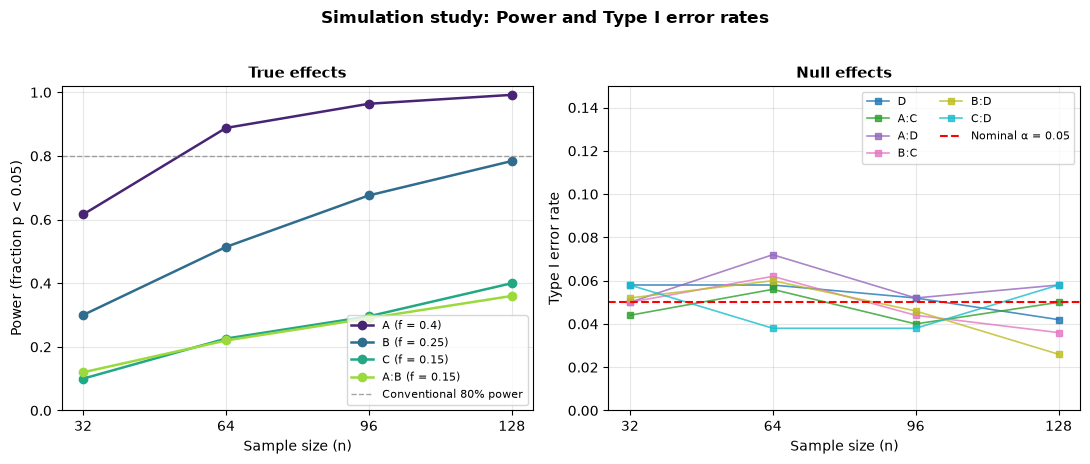


Saved: results/figures/fig1_power_curves.png


In [16]:
# Figure 1 (regenerated): Power curves.

import os
import matplotlib.pyplot as plt
import numpy as np

RESULTS_DIR = 'results'
FIGURES_DIR = os.path.join(RESULTS_DIR, 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

SAMPLE_SIZES = [32, 64, 96, 128]
FACTOR_NAMES = ['A', 'B', 'C', 'D']
EFFECTS = {
    'A': 0.40, 'B': 0.25, 'C': 0.15, 'D': 0.00,
    'A:B': 0.15, 'A:C': 0.00, 'A:D': 0.00,
    'B:C': 0.00, 'B:D': 0.00, 'C:D': 0.00,
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Left panel: true effects
true_effects = [e for e in EFFECTS if EFFECTS[e] > 0]
colors_true = plt.cm.viridis(np.linspace(0.1, 0.85, len(true_effects)))

for eff, color in zip(true_effects, colors_true):
    powers = [agg[n]['power']['power'][eff] for n in SAMPLE_SIZES]
    axes[0].plot(SAMPLE_SIZES, powers, marker='o', color=color,
                 linewidth=1.8, markersize=6,
                 label=f"{eff} (f = {EFFECTS[eff]})")

axes[0].axhline(0.80, color='gray', linestyle='--',
                linewidth=1, alpha=0.7, label='Conventional 80% power')
axes[0].set_xlabel('Sample size (n)', fontsize=10)
axes[0].set_ylabel('Power (fraction p < 0.05)', fontsize=10)
axes[0].set_title('True effects', fontsize=11, fontweight='bold')
axes[0].set_xticks(SAMPLE_SIZES)
axes[0].set_ylim(0, 1.02)
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8, loc='lower right')

# Right panel: null effects
null_effects = [e for e in EFFECTS if EFFECTS[e] == 0]
colors_null = plt.cm.tab10(np.linspace(0, 1, len(null_effects)))

for eff, color in zip(null_effects, colors_null):
    powers = [agg[n]['power']['power'][eff] for n in SAMPLE_SIZES]
    axes[1].plot(SAMPLE_SIZES, powers, marker='s', color=color,
                 linewidth=1.2, markersize=5, alpha=0.8, label=eff)

axes[1].axhline(0.05, color='red', linestyle='--',
                linewidth=1.5, label='Nominal α = 0.05')
axes[1].set_xlabel('Sample size (n)', fontsize=10)
axes[1].set_ylabel('Type I error rate', fontsize=10)
axes[1].set_title('Null effects', fontsize=11, fontweight='bold')
axes[1].set_xticks(SAMPLE_SIZES)
axes[1].set_ylim(0, 0.15)
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8, loc='upper right', ncol=2)

fig.suptitle('Simulation study: Power and Type I error rates',
             fontsize=12, fontweight='bold', y=1.02)
fig.tight_layout()

out_path = os.path.join(FIGURES_DIR, 'fig1_power_curves.png')
fig.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"\nSaved: {out_path}")

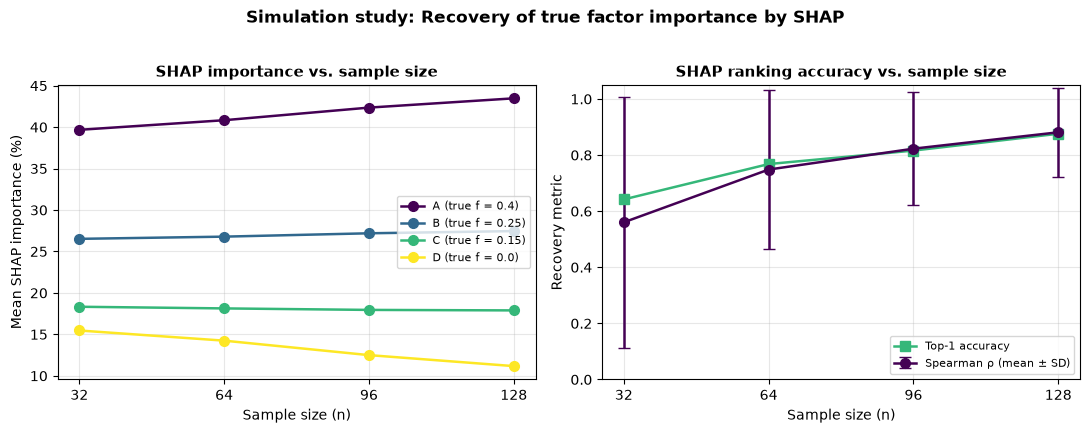


Saved: results/figures/fig2_shap_recovery.png


In [17]:
# Figure 2 (regenerated): SHAP recovery.

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

factor_colors = {'A': '#440154', 'B': '#31688e',
                 'C': '#35b779', 'D': '#fde725'}

# Left panel: SHAP % per factor
for f in FACTOR_NAMES:
    shap_vals = [agg[n]['shap_mean'][f] for n in SAMPLE_SIZES]
    axes[0].plot(SAMPLE_SIZES, shap_vals, marker='o',
                 color=factor_colors[f], linewidth=1.8, markersize=7,
                 label=f"{f} (true f = {EFFECTS[f]})")

axes[0].set_xlabel('Sample size (n)', fontsize=10)
axes[0].set_ylabel('Mean SHAP importance (%)', fontsize=10)
axes[0].set_title('SHAP importance vs. sample size',
                  fontsize=11, fontweight='bold')
axes[0].set_xticks(SAMPLE_SIZES)
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8, loc='center right')

# Right panel: rank correlation + top-1 accuracy
rank_corrs = [shap_summary[n]['rank_corr_mean'] for n in SAMPLE_SIZES]
rank_sds   = [shap_summary[n]['rank_corr_sd']   for n in SAMPLE_SIZES]
top1_accs  = [shap_summary[n]['top1_accuracy']  for n in SAMPLE_SIZES]

axes[1].errorbar(SAMPLE_SIZES, rank_corrs, yerr=rank_sds,
                 marker='o', color='#440154', linewidth=1.8,
                 markersize=7, capsize=4,
                 label='Spearman ρ (mean ± SD)')
axes[1].plot(SAMPLE_SIZES, top1_accs,
             marker='s', color='#35b779', linewidth=1.8,
             markersize=7, label='Top-1 accuracy')

axes[1].set_xlabel('Sample size (n)', fontsize=10)
axes[1].set_ylabel('Recovery metric', fontsize=10)
axes[1].set_title('SHAP ranking accuracy vs. sample size',
                  fontsize=11, fontweight='bold')
axes[1].set_xticks(SAMPLE_SIZES)
axes[1].set_ylim(0, 1.05)
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8, loc='lower right')

fig.suptitle('Simulation study: Recovery of true factor importance by SHAP',
             fontsize=12, fontweight='bold', y=1.02)
fig.tight_layout()

out_path = os.path.join(FIGURES_DIR, 'fig2_shap_recovery.png')
fig.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"\nSaved: {out_path}")

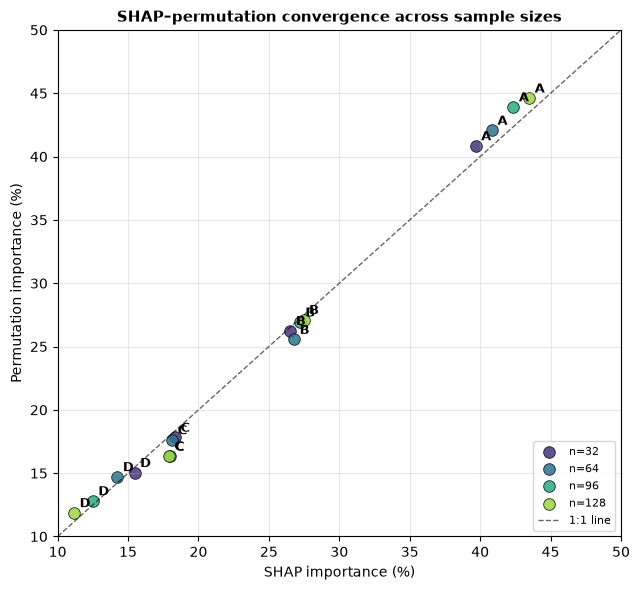


Saved: results/figures/fig3_shap_vs_perm.png

=== SHAP vs. permutation correlation per scenario ===
  n=  32   Pearson r = 1.000
  n=  64   Pearson r = 0.997
  n=  96   Pearson r = 0.997
  n= 128   Pearson r = 0.997


In [18]:
# Figure 3 (regenerated): SHAP vs. permutation convergence.

fig, ax = plt.subplots(figsize=(6.5, 6))

n_colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(SAMPLE_SIZES)))

for n, color in zip(SAMPLE_SIZES, n_colors):
    shap_m = agg[n]['shap_mean']
    perm_m = agg[n]['perm_mean']
    for f in FACTOR_NAMES:
        ax.scatter(shap_m[f], perm_m[f], s=70, color=color,
                   edgecolor='black', linewidth=0.6, alpha=0.85,
                   label=f"n={n}" if f == FACTOR_NAMES[0] else None)
        ax.annotate(f, (shap_m[f], perm_m[f]),
                    xytext=(4, 4), textcoords='offset points',
                    fontsize=9, fontweight='bold')

lims = [10, 50]
ax.plot(lims, lims, 'k--', linewidth=1, alpha=0.6, label='1:1 line')

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel('SHAP importance (%)', fontsize=10)
ax.set_ylabel('Permutation importance (%)', fontsize=10)
ax.set_title('SHAP–permutation convergence across sample sizes',
             fontsize=11, fontweight='bold')
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc='lower right')

fig.tight_layout()
out_path = os.path.join(FIGURES_DIR, 'fig3_shap_vs_perm.png')
fig.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"\nSaved: {out_path}")

# Convergence metric
print("\n=== SHAP vs. permutation correlation per scenario ===")
for n in SAMPLE_SIZES:
    shap_v = np.array([agg[n]['shap_mean'][f] for f in FACTOR_NAMES])
    perm_v = np.array([agg[n]['perm_mean'][f] for f in FACTOR_NAMES])
    r = np.corrcoef(shap_v, perm_v)[0, 1]
    print(f"  n={n:4d}   Pearson r = {r:.3f}")

In [16]:
# Load all four scenarios from disk and build the summary tables.

import pickle

scenarios = {}
for n in SAMPLE_SIZES:
    path = os.path.join(SCENARIO_DIR, f'scenario_n{n}.pkl')
    with open(path, 'rb') as f:
        scenarios[n] = pickle.load(f)
    print(f"n={n}: {len(scenarios[n])} iterations loaded")

print("\nBuilding summary tables...\n")

# Aggregate each scenario
agg = {n: aggregate_results(scenarios[n]) for n in SAMPLE_SIZES}

# ---- FULL power table (all effects, both true and null) ----
# We can reconstruct this from power_true + type_i_error, or use power_df.
# Simplest: reindex the full 'power' DataFrame.

power_table = pd.DataFrame({
    n: agg[n]['power']['power'] for n in SAMPLE_SIZES
})
power_table = power_table.reindex(list(EFFECTS.keys()))

# Add true effect column for reference
power_table.insert(0, 'true_effect', [EFFECTS[e] for e in power_table.index])

print("=== Power table (fraction of runs with p<0.05) ===\n")
print(power_table.round(3).to_string())

# ---- Type I error summary (null effects only) ----
print("\n=== Type I error summary (null effects) ===\n")
null_effects = [e for e in EFFECTS if EFFECTS[e] == 0]
tie_table = pd.DataFrame({
    n: {e: agg[n]['type_i_error'].get(e, np.nan) for e in null_effects}
    for n in SAMPLE_SIZES
})
print(tie_table.round(3).to_string())
print(f"\nIdeal value: 0.05")
print(f"Mean across all null effects and scenarios: "
      f"{tie_table.values.mean():.3f}")

n=32: 500 iterations loaded
n=64: 500 iterations loaded
n=96: 500 iterations loaded
n=128: 500 iterations loaded

Building summary tables...

=== Power table (fraction of runs with p<0.05) ===

     true_effect     32     64     96    128
A           0.40  0.616  0.888  0.964  0.992
B           0.25  0.300  0.514  0.676  0.784
C           0.15  0.100  0.226  0.296  0.400
D           0.00  0.058  0.058  0.052  0.042
A:B         0.15  0.120  0.220  0.290  0.360
A:C         0.00  0.044  0.056  0.040  0.050
A:D         0.00  0.050  0.072  0.052  0.058
B:C         0.00  0.050  0.062  0.044  0.036
B:D         0.00  0.052  0.060  0.046  0.026
C:D         0.00  0.058  0.038  0.038  0.058

=== Type I error summary (null effects) ===

       32     64     96     128
D    0.058  0.058  0.052  0.042
A:C  0.044  0.056  0.040  0.050
A:D  0.050  0.072  0.052  0.058
B:C  0.050  0.062  0.044  0.036
B:D  0.052  0.060  0.046  0.026
C:D  0.058  0.038  0.038  0.058

Ideal value: 0.05
Mean across all null e

In [17]:
# SHAP recovery: does SHAP rank the true factors correctly?
# For each scenario, compute:
#   - mean SHAP importance per factor
#   - Spearman correlation with true effect sizes
#   - fraction of runs where the SHAP ranking matched the true ranking

print("=== SHAP recovery analysis ===\n")

shap_summary = {}

for n in SAMPLE_SIZES:
    df_res = scenarios[n]
    shap_cols = [f'shap__{f}' for f in FACTOR_NAMES]
    
    # Mean SHAP per factor
    shap_mean = df_res[shap_cols].mean()
    shap_mean.index = [c.replace('shap__', '') for c in shap_mean.index]
    
    # True effects for main factors only
    true_vec = np.array([abs(EFFECTS[f]) for f in FACTOR_NAMES])
    
    # Rank correlation per iteration
    def spearman_with_truth(row):
        shap_vec = np.array([row[f'shap__{f}'] for f in FACTOR_NAMES])
        if np.std(shap_vec) == 0:
            return np.nan
        return stats.spearmanr(true_vec, shap_vec).statistic
    
    rank_corrs = df_res.apply(spearman_with_truth, axis=1)
    
    # Exact top-1 recovery: is A ranked highest in SHAP?
    top1_hits = df_res.apply(
        lambda row: (np.argmax([row[f'shap__{f}'] for f in FACTOR_NAMES]) == 0),
        axis=1).mean()
    
    shap_summary[n] = {
        'shap_mean': shap_mean,
        'rank_corr_mean': rank_corrs.mean(),
        'rank_corr_sd': rank_corrs.std(),
        'top1_accuracy': top1_hits,
    }
    
    print(f"n = {n}")
    print(f"  Mean SHAP (%): " + 
          ", ".join([f"{f}={shap_mean[f]:.1f}" for f in FACTOR_NAMES]))
    print(f"  Rank correlation with truth: "
          f"{rank_corrs.mean():.3f} ± {rank_corrs.std():.3f}")
    print(f"  A-ranked-highest accuracy:   {top1_hits:.3f}")
    print()

# Summary table across sample sizes
print("\n=== Summary table ===\n")
summary_df = pd.DataFrame({
    'n': SAMPLE_SIZES,
    'A SHAP %': [shap_summary[n]['shap_mean']['A'] for n in SAMPLE_SIZES],
    'B SHAP %': [shap_summary[n]['shap_mean']['B'] for n in SAMPLE_SIZES],
    'C SHAP %': [shap_summary[n]['shap_mean']['C'] for n in SAMPLE_SIZES],
    'D SHAP %': [shap_summary[n]['shap_mean']['D'] for n in SAMPLE_SIZES],
    'Rank ρ':   [shap_summary[n]['rank_corr_mean'] for n in SAMPLE_SIZES],
    'Top-1 acc':[shap_summary[n]['top1_accuracy'] for n in SAMPLE_SIZES],
})
print(summary_df.round(3).to_string(index=False))

=== SHAP recovery analysis ===

n = 32
  Mean SHAP (%): A=39.5, B=26.6, C=18.4, D=15.4
  Rank correlation with truth: 0.560 ± 0.457
  A-ranked-highest accuracy:   0.648

n = 64
  Mean SHAP (%): A=40.7, B=26.8, C=18.2, D=14.3
  Rank correlation with truth: 0.751 ± 0.277
  A-ranked-highest accuracy:   0.760

n = 96
  Mean SHAP (%): A=42.2, B=27.3, C=18.0, D=12.5
  Rank correlation with truth: 0.822 ± 0.203
  A-ranked-highest accuracy:   0.814

n = 128
  Mean SHAP (%): A=43.4, B=27.5, C=17.9, D=11.2
  Rank correlation with truth: 0.878 ± 0.157
  A-ranked-highest accuracy:   0.880


=== Summary table ===

  n  A SHAP %  B SHAP %  C SHAP %  D SHAP %  Rank ρ  Top-1 acc
 32    39.528    26.648    18.421    15.403   0.560      0.648
 64    40.717    26.845    18.162    14.276   0.751      0.760
 96    42.218    27.287    17.959    12.536   0.822      0.814
128    43.418    27.474    17.880    11.228   0.878      0.880


In [18]:
# Save key tables to CSV for the manuscript.

# 1. Power table
power_table.to_csv(os.path.join(RESULTS_DIR, 'power_table.csv'))
print(f"Saved power_table.csv")

# 2. Type I error table
tie_table.to_csv(os.path.join(RESULTS_DIR, 'type_i_error.csv'))
print(f"Saved type_i_error.csv")

# 3. SHAP summary
summary_df.to_csv(os.path.join(RESULTS_DIR, 'shap_recovery.csv'), index=False)
print(f"Saved shap_recovery.csv")

# 4. Full SHAP means per scenario (for figure)
shap_means_by_n = pd.DataFrame({
    n: agg[n]['shap_mean'] for n in SAMPLE_SIZES
})
shap_means_by_n.to_csv(os.path.join(RESULTS_DIR, 'shap_means_by_n.csv'))
print(f"Saved shap_means_by_n.csv")

# 5. Permutation means per scenario
perm_means_by_n = pd.DataFrame({
    n: agg[n]['perm_mean'] for n in SAMPLE_SIZES
})
perm_means_by_n.to_csv(os.path.join(RESULTS_DIR, 'perm_means_by_n.csv'))
print(f"Saved perm_means_by_n.csv")

print(f"\nAll tables saved to {os.path.abspath(RESULTS_DIR)}")

Saved power_table.csv
Saved type_i_error.csv
Saved shap_recovery.csv
Saved shap_means_by_n.csv
Saved perm_means_by_n.csv

All tables saved to /home/mb/ML_analysis/streamlit_app/simulation/results


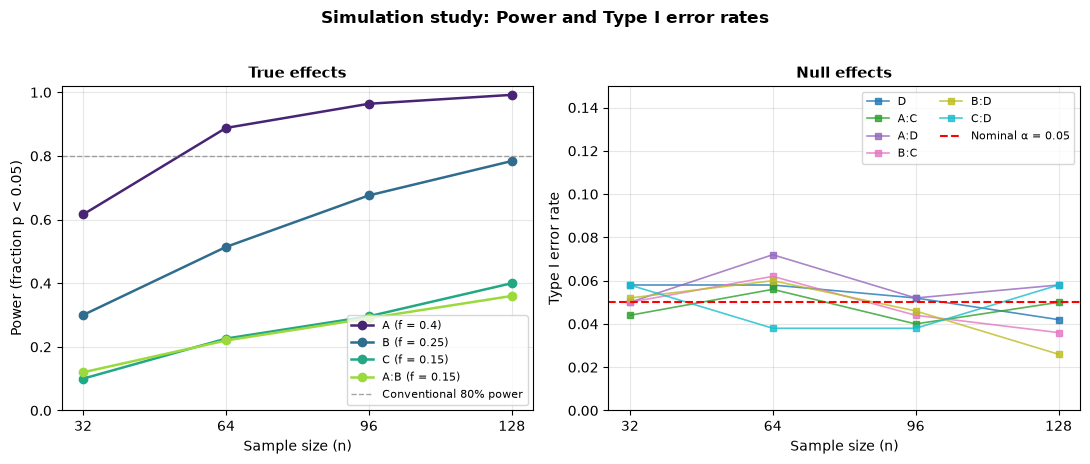


Saved: results/figures/fig1_power_curves.png


In [19]:
# Figure 1: Power curves.
# Left panel: true effects (rising curves).
# Right panel: null effects (flat near 0.05).

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# ---- Left panel: true effects ----
true_effects = [e for e in EFFECTS if EFFECTS[e] > 0]
colors_true = plt.cm.viridis(np.linspace(0.1, 0.85, len(true_effects)))

for eff, color in zip(true_effects, colors_true):
    powers = [agg[n]['power']['power'][eff] for n in SAMPLE_SIZES]
    axes[0].plot(SAMPLE_SIZES, powers, marker='o', color=color,
                 linewidth=1.8, markersize=6,
                 label=f"{eff} (f = {EFFECTS[eff]})")

axes[0].axhline(0.80, color='gray', linestyle='--',
                linewidth=1, alpha=0.7, label='Conventional 80% power')
axes[0].set_xlabel('Sample size (n)', fontsize=10)
axes[0].set_ylabel('Power (fraction p < 0.05)', fontsize=10)
axes[0].set_title('True effects', fontsize=11, fontweight='bold')
axes[0].set_xticks(SAMPLE_SIZES)
axes[0].set_ylim(0, 1.02)
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8, loc='lower right')

# ---- Right panel: null effects ----
null_effects = [e for e in EFFECTS if EFFECTS[e] == 0]
colors_null = plt.cm.tab10(np.linspace(0, 1, len(null_effects)))

for eff, color in zip(null_effects, colors_null):
    powers = [agg[n]['power']['power'][eff] for n in SAMPLE_SIZES]
    axes[1].plot(SAMPLE_SIZES, powers, marker='s', color=color,
                 linewidth=1.2, markersize=5, alpha=0.8, label=eff)

axes[1].axhline(0.05, color='red', linestyle='--',
                linewidth=1.5, label='Nominal α = 0.05')
axes[1].set_xlabel('Sample size (n)', fontsize=10)
axes[1].set_ylabel('Type I error rate', fontsize=10)
axes[1].set_title('Null effects', fontsize=11, fontweight='bold')
axes[1].set_xticks(SAMPLE_SIZES)
axes[1].set_ylim(0, 0.15)
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8, loc='upper right', ncol=2)

fig.suptitle('Simulation study: Power and Type I error rates',
             fontsize=12, fontweight='bold', y=1.02)
fig.tight_layout()

out_path = os.path.join(FIGURES_DIR, 'fig1_power_curves.png')
fig.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"\nSaved: {out_path}")

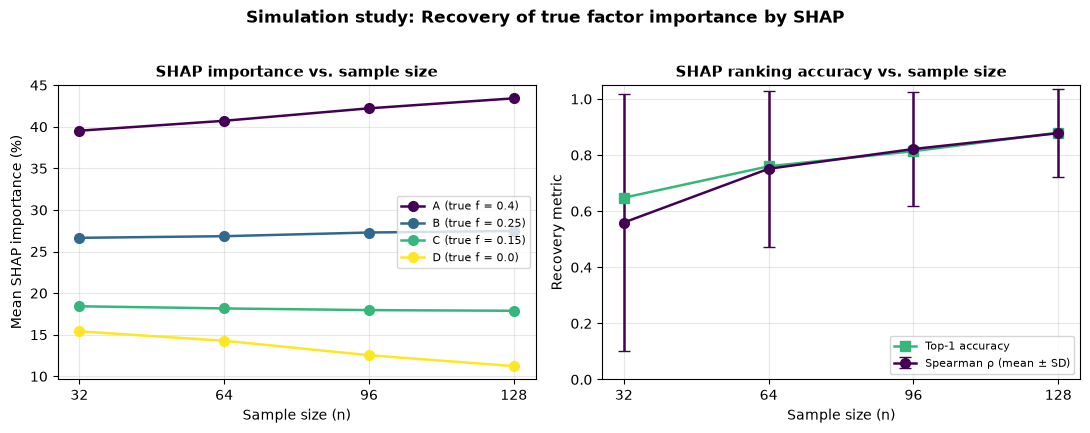


Saved: results/figures/fig2_shap_recovery.png


In [20]:
# Figure 2: SHAP recovery.
# Left panel: mean SHAP importance per factor across n.
# Right panel: rank correlation and top-1 accuracy vs. n.

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

# ---- Left panel: mean SHAP % per factor across n ----
factor_colors = {'A': '#440154', 'B': '#31688e',
                 'C': '#35b779', 'D': '#fde725'}

for f in FACTOR_NAMES:
    shap_vals = [agg[n]['shap_mean'][f] for n in SAMPLE_SIZES]
    axes[0].plot(SAMPLE_SIZES, shap_vals, marker='o',
                 color=factor_colors[f], linewidth=1.8, markersize=7,
                 label=f"{f} (true f = {EFFECTS[f]})")

axes[0].set_xlabel('Sample size (n)', fontsize=10)
axes[0].set_ylabel('Mean SHAP importance (%)', fontsize=10)
axes[0].set_title('SHAP importance vs. sample size',
                  fontsize=11, fontweight='bold')
axes[0].set_xticks(SAMPLE_SIZES)
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8, loc='center right')

# ---- Right panel: rank correlation and top-1 accuracy ----
rank_corrs = [shap_summary[n]['rank_corr_mean'] for n in SAMPLE_SIZES]
rank_sds   = [shap_summary[n]['rank_corr_sd']   for n in SAMPLE_SIZES]
top1_accs  = [shap_summary[n]['top1_accuracy']  for n in SAMPLE_SIZES]

axes[1].errorbar(SAMPLE_SIZES, rank_corrs, yerr=rank_sds,
                 marker='o', color='#440154', linewidth=1.8,
                 markersize=7, capsize=4,
                 label='Spearman ρ (mean ± SD)')
axes[1].plot(SAMPLE_SIZES, top1_accs,
             marker='s', color='#35b779', linewidth=1.8,
             markersize=7, label='Top-1 accuracy')

axes[1].set_xlabel('Sample size (n)', fontsize=10)
axes[1].set_ylabel('Recovery metric', fontsize=10)
axes[1].set_title('SHAP ranking accuracy vs. sample size',
                  fontsize=11, fontweight='bold')
axes[1].set_xticks(SAMPLE_SIZES)
axes[1].set_ylim(0, 1.05)
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8, loc='lower right')

fig.suptitle('Simulation study: Recovery of true factor importance by SHAP',
             fontsize=12, fontweight='bold', y=1.02)
fig.tight_layout()

out_path = os.path.join(FIGURES_DIR, 'fig2_shap_recovery.png')
fig.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"\nSaved: {out_path}")

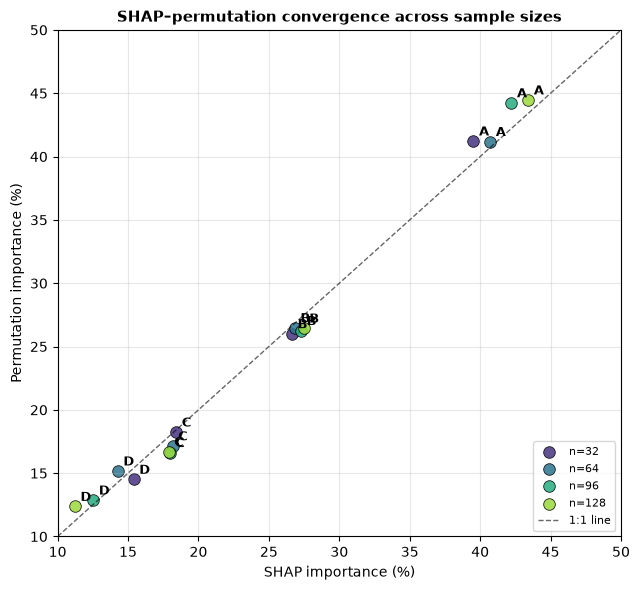


Saved: results/figures/fig3_shap_vs_perm.png

=== SHAP vs. permutation correlation per scenario ===
  n=  32   Pearson r = 0.999
  n=  64   Pearson r = 0.997
  n=  96   Pearson r = 0.996
  n= 128   Pearson r = 0.996


In [21]:
# Figure 3: SHAP vs. permutation importance convergence.
# Scatter of mean importance values from the two methods, colored by n.

fig, ax = plt.subplots(figsize=(6.5, 6))

n_colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(SAMPLE_SIZES)))

for n, color in zip(SAMPLE_SIZES, n_colors):
    shap_m = agg[n]['shap_mean']
    perm_m = agg[n]['perm_mean']
    for f in FACTOR_NAMES:
        ax.scatter(shap_m[f], perm_m[f], s=70, color=color,
                   edgecolor='black', linewidth=0.6, alpha=0.85,
                   label=f"n={n}" if f == FACTOR_NAMES[0] else None)
        ax.annotate(f, (shap_m[f], perm_m[f]),
                    xytext=(4, 4), textcoords='offset points',
                    fontsize=9, fontweight='bold')

# 1:1 reference line
lims = [10, 50]
ax.plot(lims, lims, 'k--', linewidth=1, alpha=0.6, label='1:1 line')

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel('SHAP importance (%)', fontsize=10)
ax.set_ylabel('Permutation importance (%)', fontsize=10)
ax.set_title('SHAP–permutation convergence across sample sizes',
             fontsize=11, fontweight='bold')
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc='lower right')

fig.tight_layout()
out_path = os.path.join(FIGURES_DIR, 'fig3_shap_vs_perm.png')
fig.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"\nSaved: {out_path}")

# Numerical convergence metric: Pearson r between SHAP and permutation means
print("\n=== SHAP vs. permutation correlation per scenario ===")
for n in SAMPLE_SIZES:
    shap_v = np.array([agg[n]['shap_mean'][f] for f in FACTOR_NAMES])
    perm_v = np.array([agg[n]['perm_mean'][f] for f in FACTOR_NAMES])
    r = np.corrcoef(shap_v, perm_v)[0, 1]
    print(f"  n={n:4d}   Pearson r = {r:.3f}")

In [26]:
# Save 5 simulated datasets for pipeline verification
VERIFY_DIR = 'results/verification'
os.makedirs(VERIFY_DIR, exist_ok=True)

VERIFY_SEEDS = [101, 202, 303, 404, 505]
VERIFY_N = 64

verify_meta = []
for s in VERIFY_SEEDS:
    df_v = generate_dataset(n_total=VERIFY_N, effects=EFFECTS,
                            residual_sd=RESIDUAL_SD, seed=s)
    df_v = df_v.rename(columns={
        'A': 'FactorA',
        'B': 'FactorB',
        'C': 'FactorC',
        'D': 'FactorD',
        'Y': 'ResponseY'
    })
    path = os.path.join(VERIFY_DIR, f'verify_seed{s}.csv')
    df_v.to_csv(path, index=False)
    verify_meta.append({'seed': s, 'path': path, 'n': VERIFY_N})

pd.DataFrame(verify_meta).to_csv(
    os.path.join(VERIFY_DIR, 'verification_index.csv'), index=False)
print(f"Saved {len(VERIFY_SEEDS)} CSVs to {VERIFY_DIR}")

# Show column names of one file
print("\nColumns in verify_seed101.csv:")
print(pd.read_csv(os.path.join(VERIFY_DIR, 'verify_seed101.csv')).columns.tolist())

Saved 5 CSVs to results/verification

Columns in verify_seed101.csv:
['FactorA', 'FactorB', 'FactorC', 'FactorD', 'ResponseY']
